# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import meshio
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

# make data

In [2]:
X_r, X_data, u_data = gen_train_data(1_000_000,5_000,5_000)

In [3]:
X_r

<tf.Tensor: shape=(1000000, 3), dtype=float32, numpy=
array([[ 0.8759254 ,  0.33248448, -1.8287172 ],
       [ 0.61969936, -1.6722422 ,  1.4410391 ],
       [ 1.6061722 ,  2.1895494 , -0.07318926],
       ...,
       [ 0.67869866, -0.5702462 ,  2.5379324 ],
       [ 0.8784478 , -0.4736209 , -0.9082525 ],
       [ 2.37742   , -0.13518047,  2.2840357 ]], dtype=float32)>

In [4]:
all_times = [700]
for index, t in enumerate(all_times):

        # load data from files
        reader = meshio.read(DATA_PATH+'tiltC'+str(t)+'.vtk')
        x = reader.points
        reader = meshio.read(DATA_PATH+'tiltphi'+str(t)+'.vtk')
        phi = reader.point_data['stream']
        reader = meshio.read(DATA_PATH+'tiltpsi'+str(t)+'.vtk')
        psi = reader.point_data['champ']

        my_t = (all_times[index] - all_times[0])/100
        X_data1 = tf.concat([my_t*tf.ones((len(x),1), dtype=DTYPE), x[:,0:1], x[:,1:2]], axis=1)
        u_data1 = np.vstack((phi, psi)).T
        u_data1 = tf.cast(u_data1, DTYPE)

        if index==0:
            X_data, u_data = X_data1, u_data1
        else:
            X_data = tf.concat([X_data,X_data1],0)
            u_data = tf.concat([u_data,u_data1],0)

X_data, u_data

(<tf.Tensor: shape=(5706, 3), dtype=float32, numpy=
 array([[ 0.        , -3.        ,  3.        ],
        [ 0.        , -2.8       ,  3.        ],
        [ 0.        , -2.8774338 ,  2.868292  ],
        ...,
        [ 0.        ,  0.3861511 , -0.05844375],
        [ 0.        ,  0.35041127, -0.08620989],
        [ 0.        ,  0.3838803 , -0.08545815]], dtype=float32)>,
 <tf.Tensor: shape=(5706, 2), dtype=float32, numpy=
 array([[-6.7837279e-38, -2.8333333e+00],
        [-7.4541236e-35, -2.8218527e+00],
        [-8.9286550e-05, -2.6944208e+00],
        ...,
        [ 1.4521615e-01, -3.3966118e-01],
        [ 1.4366658e-01, -3.8454068e-01],
        [ 1.3816142e-01, -3.8674164e-01]], dtype=float32)>)

# training

In [ ]:
model = PhysicsInformedNN(lb, ub, output_dim=2, num_hidden_layers=8, num_neurons_per_layer=128, activation='tanh')
model.build(input_shape=(None,3))
model.load_weights(WEIGHT_PATH+'best_weight_MHD_2var.h5')

#solver = PINNSolver(model, batch_size = 1_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=200,
    decay_rate=0.98,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, [X_data], [u_data])
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('MHD_2var')

Epoch 01_700: 

                    phi_r1       5.1293e-04  
                    phi_r2       6.2398e-03
                    phi_0        3.8536e-03
                    total_loss   1.0606e-02


<AxesSubplot:xlabel='Iteration', ylabel='Loss'>

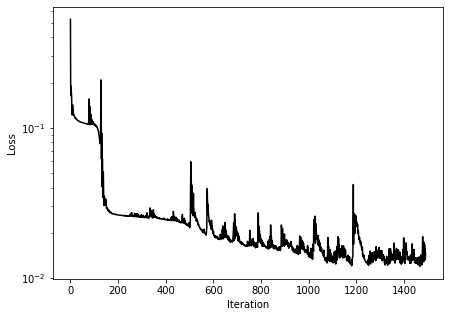

In [6]:
solver.plot_loss_history()

# Check results

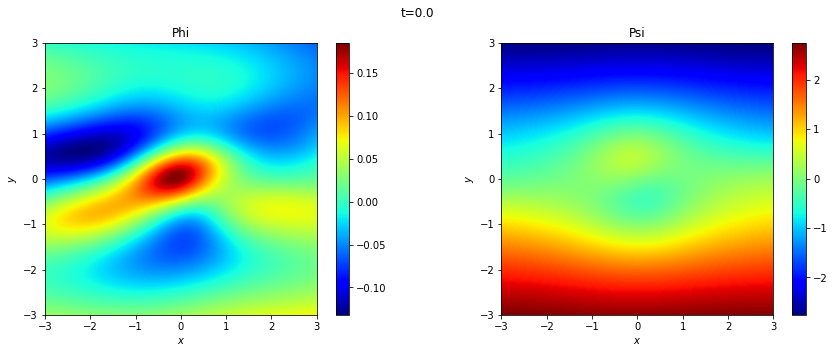

In [12]:
N = 500
t = 0.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

phi, psi = u[:,0:1], u[:,1:2]

# reshape for plotting
phi = phi.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
axs = axs.flatten()

# plot phi
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Phi')

# plot psi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Psi')

#fig.tight_layout()
plt.suptitle('t={}'.format(t))
plt.show()